In [15]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
import seaborn as sns
import matplotlib.pyplot as plt

from tensorflow.keras import layers, models
from tensorflow.keras.applications import InceptionV3

from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

from sklearn.utils.class_weight import compute_class_weight
from imblearn.over_sampling import RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler
from imblearn.combine import SMOTETomek
from collections import Counter
from imblearn.combine import SMOTEENN


In [16]:

TRAIN_GROUNDTRUTH_PATH = "data/train/ISIC_2019_Training_GroundTruth.csv"
TEST_GROUNDTRUTH_PATH = "ham10000/HAM10000_Test_GroundTruth_Updated.csv"
TEST2_GROUNDTRUTH_PATH = "data/test/ISIC_2019_Test_GroundTruth.csv"


TRAIN_IMAGE_DIR = "/Users/mac/Development/diploma/skin-mutation-detection/data/train/ISIC_2019_Training_Input"  
TEST_IMAGE_DIR = "/Users/mac/Development/diploma/skin-mutation-detection/ham10000/HAM10000_images_part_12"  
TEST2_IMAGE_DIR = "/Users/mac/Development/diploma/skin-mutation-detection/data/test/ISIC_2019_Test_Input"  
IMG_SIZE = (456, 456)
BATCH_SIZE = 32
EPOCHS = 20 

LABELS = ['MEL', 'NV', 'BCC', 'AK', 'BKL', 'DF', 'VASC', 'SCC']

In [17]:
def read_ds(gnd_path):
    """Read a dataset from CSV file and assign labels correspondingly."""
    gnd = pd.read_csv(gnd_path)
    gnd['y'] = gnd[LABELS].idxmax(axis=1)

    return gnd

def get_image_paths_and_labels(groundtruth, image_dir):
    """Generate image paths and corresponding labels from a groundtruth DataFrame."""
    image_paths = [
        os.path.join(image_dir, row['image'] + '.jpg') 
        for _, row in groundtruth.iterrows()
    ]
    labels = [
        LABELS.index(row['y']) 
        for _, row in groundtruth.iterrows()
    ]
    return image_paths, labels

train_groundtruth = read_ds(TRAIN_GROUNDTRUTH_PATH) 
test_groundtruth = read_ds(TEST_GROUNDTRUTH_PATH) 
test_groundtruth_2 = read_ds(TEST2_GROUNDTRUTH_PATH)
train_paths, train_labels = get_image_paths_and_labels(train_groundtruth, TRAIN_IMAGE_DIR)
test_paths, test_labels = get_image_paths_and_labels(test_groundtruth, TEST_IMAGE_DIR)
test_paths_2, test_labels_2 = get_image_paths_and_labels(test_groundtruth_2, TEST2_IMAGE_DIR)

In [4]:
# ros = RandomUnderSampler(sampling_strategy='auto')
# train_paths_resampled, train_labels_resampled = ros.fit_resample(np.array(train_paths).reshape(-1, 1), train_labels)
# train_paths_resampled = train_paths_resampled.flatten()
# print(f"Before downsampling: {Counter(train_labels)}")

# train_paths, train_labels = train_paths_resampled, train_labels_resampled

# print(f"After downsampling: {Counter(train_labels_resampled)}")

In [ ]:
# # Check class distribution before resampling
# print(f"Before resampling: {Counter(train_labels)}")

# # Convert paths to numeric indices (temporarily)
# indices = np.arange(len(train_paths)).reshape(-1, 1)

# # Apply SMOTETomek on labels (not paths)
# smt = SMOTETomek(random_state=42)
# indices_resampled, train_labels_resampled = smt.fit_resample(indices, train_labels)

# # Retrieve the actual file paths using the resampled indices
# train_paths_resampled = [train_paths[i] for i in indices_resampled.flatten()]
# train_labels = train_labels_resampled
# train_paths = train_paths_resampled
# # Check class distribution after resampling
# print(f"After resampling: {Counter(train_labels_resampled)}")

Before resampling: Counter({1: 12875, 0: 4522, 2: 3323, 4: 2624, 3: 867, 7: 628, 6: 253, 5: 239})
After resampling: Counter({6: 12875, 5: 12874, 7: 12874, 2: 12874, 3: 12874, 4: 12866, 0: 12859, 1: 12848})


In [18]:
from imblearn.combine import SMOTEENN
from collections import Counter
import numpy as np

# Check class distribution before resampling
print(f"Before resampling: {Counter(train_labels)}")

# Convert paths to numeric indices (temporarily)
indices = np.arange(len(train_paths)).reshape(-1, 1)

# Apply SMOTEENN on labels (not paths)
smote_enn = SMOTEENN(random_state=42)
indices_resampled, train_labels_resampled = smote_enn.fit_resample(indices, train_labels)

# Retrieve the actual file paths using the resampled indices
train_paths_resampled = [train_paths[i] for i in indices_resampled.flatten()]
train_labels = train_labels_resampled
train_paths = train_paths_resampled

# Check class distribution after resampling
print(f"After resampling: {Counter(train_labels_resampled)}")


Before resampling: Counter({1: 12875, 0: 4522, 2: 3323, 4: 2624, 3: 867, 7: 628, 6: 253, 5: 239})
After resampling: Counter({4: 1742, 0: 1582, 2: 1523, 3: 1337, 1: 955, 6: 890, 5: 739, 7: 569})


In [19]:
# Image preprocessing function
def load_image(file_path, label):
    img = tf.io.read_file(file_path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, [IMG_SIZE[0], IMG_SIZE[1]])
    img = tf.keras.applications.efficientnet.preprocess_input(img)
    return img, label

# Data Augmentation

In [20]:
import tensorflow as tf

def rotate_image(image, degrees):
    """Applies rotation without TFA using image transformation matrices."""
    radians = degrees * (3.14159265 / 180.0)
    cosine = tf.cos(radians)
    sine = tf.sin(radians)

    # Affine transformation matrix for rotation
    transform = [cosine, -sine, 0,  
                 sine, cosine, 0,  
                 0, 0]  

    # Apply transformation
    image = tf.raw_ops.ImageProjectiveTransformV2(
        images=tf.expand_dims(image, 0),  # Add batch dimension
        transforms=[transform], 
        output_shape=[IMG_SIZE[0], IMG_SIZE[1]],
        interpolation="BILINEAR"
    )
    return tf.squeeze(image)  # Remove batch dimension

def preprocess_and_augment(file_path, label):
    image = tf.io.read_file(file_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, [IMG_SIZE[0], IMG_SIZE[1]])

    # EfficientNet preprocessing
    image = tf.keras.applications.efficientnet.preprocess_input(image)

    # Data Augmentation
    image = tf.image.random_flip_left_right(image)
    image = tf.image.random_flip_up_down(image)
    image = tf.image.random_brightness(image, max_delta=0.2)
    image = tf.image.random_contrast(image, lower=0.8, upper=1.2)
    image = tf.image.random_saturation(image, lower=0.8, upper=1.2)
    image = tf.image.random_hue(image, max_delta=0.1)

    # Apply rotation (-20 to +20 degrees)
    angle = tf.random.uniform([], minval=-20, maxval=20, dtype=tf.float32)
    image = rotate_image(image, angle)

    return image, label


In [21]:
shuffle_size = 512
train_dataset = tf.data.Dataset.from_tensor_slices((train_paths, train_labels))
train_dataset = train_dataset\
    .map(preprocess_and_augment, num_parallel_calls=tf.data.AUTOTUNE)\
    .shuffle(512)\
    .batch(BATCH_SIZE)\
    .cache("train.ds")\
    .prefetch(tf.data.AUTOTUNE)

test_dataset = tf.data.Dataset.from_tensor_slices((test_paths, test_labels))
test_dataset = test_dataset\
    .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)\
    .batch(BATCH_SIZE)\
    .prefetch(tf.data.AUTOTUNE)

test_dataset_2 = tf.data.Dataset.from_tensor_slices((test_paths_2, test_labels_2))
test_dataset_2 = test_dataset_2\
    .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)\
    .batch(BATCH_SIZE)\
    .prefetch(tf.data.AUTOTUNE)

# Model

In [22]:
base_model = InceptionV3(weights="imagenet", include_top=False, input_shape=(*IMG_SIZE, 3))
base_model.trainable = False

inputs = tf.keras.Input(shape=(*IMG_SIZE, 3))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(1024, activation='relu')(x)
x = layers.Dropout(0.5)(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.5)(x)

outputs = layers.Dense(len(LABELS), activation="softmax")(x)

model = models.Model(inputs, outputs)
model.compile(
    optimizer=tf.keras.optimizers.SGD(learning_rate=0.0005, momentum=0.9),
    loss="sparse_categorical_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.SparseCategoricalAccuracy(name="sparse_accuracy"),
        tf.keras.metrics.SparseTopKCategoricalAccuracy(k=3, name="top3_accuracy")
    ]
)

In [23]:
model_path = "InceptionV3_baserun.keras"
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=model_path,
    monitor="accuracy",
    mode="max",
    save_best_only=True
)

# if os.path.exists(model_path):
#     model = tf.keras.models.load_model(model_path)

early_stop = tf.keras.callbacks.EarlyStopping(
    restore_best_weights=True,
    monitor="val_loss",
    patience=5,  
)

lr_schedule = tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, verbose=1)


In [24]:
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 456, 456, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ inception_v3 (Functional)       │ (None, 12, 12, 2048)   │    21,802,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1024)           │     2,098,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_189         │ (None, 1024)           │         4,096 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 8)              │         8,200 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,913,256 (91.22 MB)

 Trainable params: 2,108,424 (8.04 MB)

 Non-trainable params: 21,804,832 (83.18 MB)

In [25]:
# Imbalance in the dataset
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_labels),
    y=train_labels
)

# Training & Saving the Model

In [26]:
# Train the model
history = model.fit(
    train_dataset,
    validation_data=test_dataset,
    epochs=EPOCHS,
    class_weight={i: weight for i, weight in enumerate(class_weights)},
    callbacks=[checkpoint, early_stop, lr_schedule]
)

Epoch 1/20
292/292 ━━━━━━━━━━━━━━━━━━━━ 225s 752ms/step - accuracy: 0.2102 - loss: 3.0950 - sparse_accuracy: 0.2102 - top3_accuracy: 0.4786 - val_accuracy: 0.6125 - val_loss: 1.3057 - val_sparse_accuracy: 0.6125 - val_top3_accuracy: 0.7780 - learning_rate: 5.0000e-04
Epoch 2/20
292/292 ━━━━━━━━━━━━━━━━━━━━ 218s 743ms/step - accuracy: 0.4750 - loss: 1.7539 - sparse_accuracy: 0.4750 - top3_accuracy: 0.7238 - val_accuracy: 0.6768 - val_loss: 1.0429 - val_sparse_accuracy: 0.6768 - val_top3_accuracy: 0.8863 - learning_rate: 5.0000e-04
Epoch 3/20
292/292 ━━━━━━━━━━━━━━━━━━━━ 218s 743ms/step - accuracy: 0.5764 - loss: 1.4060 - sparse_accuracy: 0.5764 - top3_accuracy: 0.8013 - val_accuracy: 0.6754 - val_loss: 1.0574 - val_sparse_accuracy: 0.6754 - val_top3_accuracy: 0.9024 - learning_rate: 5.0000e-04
Epoch 4/20
292/292 ━━━━━━━━━━━━━━━━━━━━ 216s 738ms/step - accuracy: 0.6191 - loss: 1.2453 - sparse_accuracy: 0.6191 - top3_accuracy: 0.8351 - val_accuracy: 0.6763 - val_loss: 1.0188 - val_sparse_a

In [27]:
model = models.load_model('InceptionV3_baserun.keras')

In [28]:
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 456, 456, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ inception_v3 (Functional)       │ (None, 12, 12, 2048)   │    21,802,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1024)           │     2,098,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_189         │ (None, 1024)           │         4,096 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 8)              │         8,200 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26,021,682 (99.26 MB)

 Trainable params: 2,108,424 (8.04 MB)

 Non-trainable params: 21,804,832 (83.18 MB)

 Optimizer params: 2,108,426 (8.04 MB)

In [29]:
for i in model.layers:
    if i.name == 'inception_v3':
        for layer in i.layers[-100:]:
            layer.trainable = True
    if i.name == 'batch_normalization_97':
        print("batch found")
        i.trainable = False

In [30]:
model.compile(
optimizer=tf.keras.optimizers.Adam(1e-5), 
loss="sparse_categorical_crossentropy", 
metrics=[
        "accuracy",
        tf.keras.metrics.SparseCategoricalAccuracy(name="sparse_accuracy"),
        tf.keras.metrics.SparseTopKCategoricalAccuracy(k=3, name="top3_accuracy")
    ]
)

In [31]:
model_path = "InceptionV3_finetuning.keras"
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=model_path,
    monitor="accuracy",
    mode="max",
    save_best_only=True
)

In [32]:
BATCH_SIZE = 16

shuffle_size = 512
train_dataset = tf.data.Dataset.from_tensor_slices((train_paths, train_labels))
train_dataset = train_dataset\
    .map(preprocess_and_augment, num_parallel_calls=tf.data.AUTOTUNE)\
    .shuffle(512)\
    .batch(BATCH_SIZE)\
    .cache("train.ds")\
    .prefetch(tf.data.AUTOTUNE)

test_dataset = tf.data.Dataset.from_tensor_slices((test_paths, test_labels))
test_dataset = test_dataset\
    .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)\
    .batch(BATCH_SIZE)\
    .prefetch(tf.data.AUTOTUNE)

test_dataset_2 = tf.data.Dataset.from_tensor_slices((test_paths_2, test_labels_2))
test_dataset_2 = test_dataset_2\
    .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)\
    .batch(BATCH_SIZE)\
    .prefetch(tf.data.AUTOTUNE)

In [33]:
history_finetuning = model.fit(
    train_dataset,
    validation_data=test_dataset,
    epochs=EPOCHS,
    class_weight={i: weight for i, weight in enumerate(class_weights)},
    callbacks=[checkpoint, early_stop, lr_schedule]
)

Epoch 1/20


584/584 ━━━━━━━━━━━━━━━━━━━━ 502s 829ms/step - accuracy: 0.6651 - loss: 1.0349 - sparse_accuracy: 0.6651 - top3_accuracy: 0.8952 - val_accuracy: 0.6695 - val_loss: 1.1386 - val_sparse_accuracy: 0.6695 - val_top3_accuracy: 0.8978 - learning_rate: 1.0000e-05
Epoch 2/20
584/584 ━━━━━━━━━━━━━━━━━━━━ 478s 817ms/step - accuracy: 0.6484 - loss: 1.0115 - sparse_accuracy: 0.6484 - top3_accuracy: 0.8848 - val_accuracy: 0.6786 - val_loss: 1.0831 - val_sparse_accuracy: 0.6786 - val_top3_accuracy: 0.8714 - learning_rate: 1.0000e-05
Epoch 3/20
584/584 ━━━━━━━━━━━━━━━━━━━━ 478s 816ms/step - accuracy: 0.6516 - loss: 0.9786 - sparse_accuracy: 0.6516 - top3_accuracy: 0.8886 - val_accuracy: 0.6832 - val_loss: 1.0413 - val_sparse_accuracy: 0.6832 - val_top3_accuracy: 0.8754 - learning_rate: 1.0000e-05
Epoch 4/20
584/584 ━━━━━━━━━━━━━━━━━━━━ 478s 816ms/step - accuracy: 0.6704 - loss: 0.9105 - sparse_accuracy: 0.6704 - top3_accuracy: 0.9016 - val_accuracy: 0.6832 - val_loss: 1.0272 - val_sparse_accuracy: 0.

### HAM10000

In [ ]:
# HAM10000
result = model.evaluate(test_dataset)


626/626 ━━━━━━━━━━━━━━━━━━━━ 232s 369ms/step - accuracy: 0.5008 - loss: 1.3804 - sparse_accuracy: 0.5008 - top3_accuracy: 0.8872


<function print(*args, sep=' ', end='\n', file=None, flush=False)>

In [46]:
print(result)

[1.0808604955673218, 0.6853719353675842, 0.6853719353675842, 0.8903644680976868]


In [34]:
y_true = np.concatenate([y for _, y in test_dataset], axis=0)
y_pred = model.predict(test_dataset)
y_pred = np.argmax(y_pred, axis=1)

2025-03-12 08:32:47.557633: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


626/626 ━━━━━━━━━━━━━━━━━━━━ 128s 196ms/step


In [38]:
score_report = classification_report(y_true, y_pred, target_names=[LABELS[i] for i in range(8)], zero_division=0)
print(score_report)

              precision    recall  f1-score   support

         MEL       0.46      0.15      0.23      1113
          NV       0.75      0.96      0.84      6705
         BCC       0.25      0.39      0.30       514
          AK       0.00      0.00      0.00       327
         BKL       0.44      0.02      0.03      1099
          DF       0.00      0.00      0.00       115
        VASC       0.00      0.00      0.00       142
         SCC       0.00      0.00      0.00         0

    accuracy                           0.68     10015
   macro avg       0.24      0.19      0.18     10015
weighted avg       0.61      0.68      0.61     10015



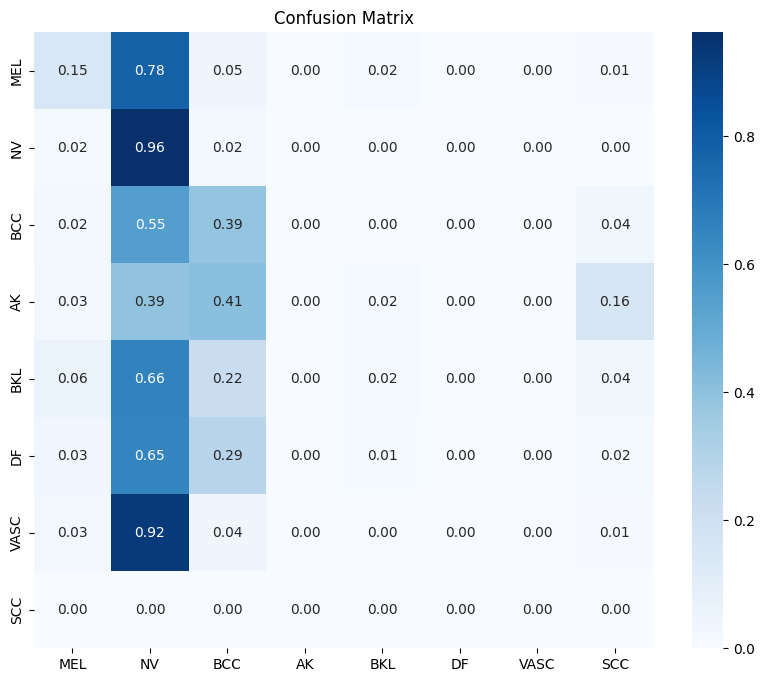

In [36]:
conf_matrix = confusion_matrix(y_true, y_pred, normalize="true")
plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, cmap="Blues", fmt=".2f",
            xticklabels=LABELS, yticklabels=LABELS)
plt.title("Confusion Matrix")
plt.show()

### ISIC 2019

In [37]:
# ISIC 2019
test_loss, test_accuracy = model.evaluate(test_dataset_2)
print(f"HAM10000 Test Accuracy: {test_accuracy}")
print(f"HAM10000 Test Loss: {test_loss}")

515/515 ━━━━━━━━━━━━━━━━━━━━ 100s 193ms/step - accuracy: 0.4936 - loss: 1.6373 - sparse_accuracy: 0.4936 - top3_accuracy: 0.7620


ValueError: too many values to unpack (expected 2)

In [39]:
y2_true = np.concatenate([y for _, y in test_dataset_2], axis=0)
y2_pred = model.predict(test_dataset_2)
y2_pred = np.argmax(y2_pred, axis=1)

2025-03-12 10:17:09.491948: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


515/515 ━━━━━━━━━━━━━━━━━━━━ 99s 192ms/step


In [40]:
score_report = classification_report(y2_true, 
                                     y2_pred, 
                                     target_names=[LABELS[i] for i in range(8)])
print(score_report)

              precision    recall  f1-score   support

         MEL       0.69      0.15      0.25      3374
          NV       0.42      0.90      0.57      2495
         BCC       0.25      0.44      0.32       975
          AK       0.06      0.01      0.01       374
         BKL       0.33      0.02      0.03       660
          DF       0.00      0.00      0.00        91
        VASC       0.00      0.00      0.00       104
         SCC       0.07      0.14      0.10       165

    accuracy                           0.39      8238
   macro avg       0.23      0.21      0.16      8238
weighted avg       0.47      0.39      0.32      8238



/Users/mac/Library/Caches/pypoetry/virtualenvs/diploma-JhBIondL-py3.11/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/mac/Library/Caches/pypoetry/virtualenvs/diploma-JhBIondL-py3.11/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/mac/Library/Caches/pypoetry/virtualenvs/diploma-JhBIondL-py3.11/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples

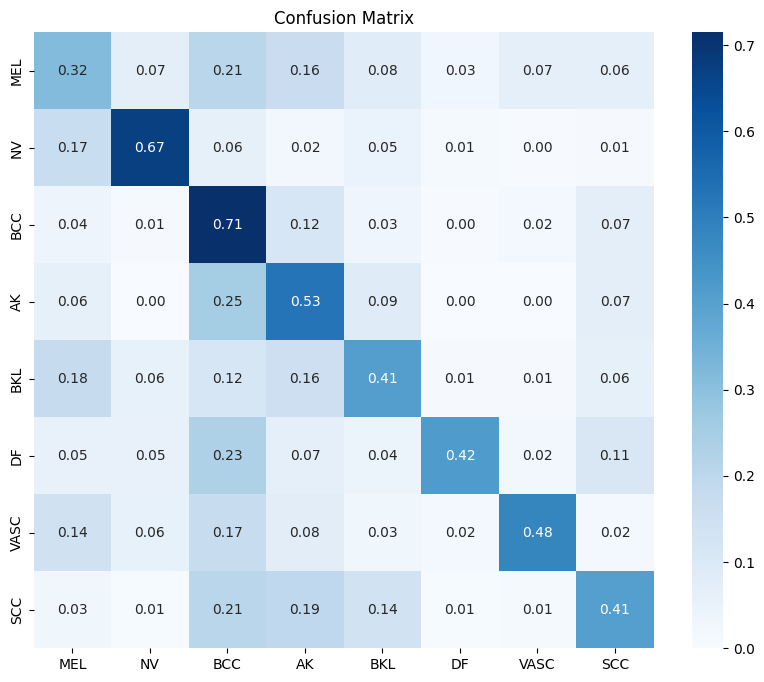

In [ ]:
conf_matrix = confusion_matrix(y2_true, 
                               y2_pred, 
                               normalize="true")
plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, cmap="Blues", fmt=".2f",
            xticklabels=LABELS, yticklabels=LABELS)
plt.title("Confusion Matrix")
plt.show()

In [32]:
import os
import random
import matplotlib.pyplot as plt
import tensorflow as tf
import numpy as np
from tensorflow.keras.preprocessing import image
import pandas as pd

# Define class labels (update according to your dataset)
LABELS = ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']

# Load a trained model (update with your model path)
MODEL_PATH = "your_model.h5"
model = tf.keras.models.load_model(MODEL_PATH)

# Function to preprocess image
def preprocess_image(img_path, img_size=(224, 224)):  # Adjust size if needed
    img = image.load_img(img_path, target_size=img_size)
    img_array = image.img_to_array(img) / 255.0  # Normalize to [0,1]
    img_array = np.expand_dims(img_array, axis=0)  # Add batch dimension
    return img_array

# Group the images by their labels
def group_images_by_label(paths, labels):
    grouped = {label: [] for label in LABELS}
    for path, label in zip(paths, labels):
        grouped[LABELS[label]].append(path)
    return grouped

# Get grouped images for each dataset
grouped_test_1 = group_images_by_label(test_paths, test_labels)
grouped_test_2 = group_images_by_label(test_paths_2, test_labels_2)

# Select one image per label from each dataset
selected_images_1 = {label: random.choice(paths) for label, paths in grouped_test_1.items()}
selected_images_2 = {label: random.choice(paths) for label, paths in grouped_test_2.items()}

# Prepare a figure for displaying images
fig, axes = plt.subplots(2, len(LABELS), figsize=(20, 10))

# Make predictions and display images
for idx, label in enumerate(LABELS):
    # Get the selected images
    img_1_path = selected_images_1[label]
    img_2_path = selected_images_2[label]

    # Preprocess and predict for each image
    img_1 = preprocess_image(img_1_path)
    img_2 = preprocess_image(img_2_path)
    
    pred_1 = model.predict(img_1)
    pred_2 = model.predict(img_2)
    
    # Get predicted labels
    label_1 = LABELS[np.argmax(pred_1)]
    label_2 = LABELS[np.argmax(pred_2)]

    # Plot the images with predictions
    axes[0, idx].imshow(image.load_img(img_1_path))
    axes[0, idx].set_title(f"Dataset 1\nPred: {label_1}")
    axes[0, idx].axis('off')
    
    axes[1, idx].imshow(image.load_img(img_2_path))
    axes[1, idx].set_title(f"Dataset 2\nPred: {label_2}")
    axes[1, idx].axis('off')

plt.tight_layout()
plt.show()


FileNotFoundError: [Errno 2] Unable to open file (unable to open file: name = 'your_model.h5', errno = 2, error message = 'No such file or directory', flags = 0, o_flags = 0)

In [ ]:
memory_info = tf.config.experimental.get_memory_info('GPU:0')

print("Memory Usage (Bytes):", memory_info)